# Where can covariance beat expression?

**Goal.** Find a case where matching on mean expression fails and Spindle's covariance works. Mean expression cannot see
*which cells* express a gene, so the case must be co-expression: genes that are on **in the same cells** (a cell
state) versus the same genes on in different cells. Earlier tests (15 and 24 Oct) found d_B variance-dominated, and
variance follows the mean for counts. So this test also tries a correlation-only distance and a variance + correlation
split, and looks at whether bigger tiles make per-tile correlations reliable enough to use.

**The decoy.** Take a tile and, inside each annotated cell type (`Cluster`, 20 types), shuffle every gene's values
among that type's cells independently. The decoy keeps the tile's composition, every gene's mean and variance, and
every type's mean profile **exactly**, but loses co-expression within cell types. Expression and variances cannot
tell a tile from its decoy.

**Distances** (all on each tile size's production layout, in the index tile's niche blocks, as in Spindle):

| Name | Distance |
|---|---|
| Expression | ‖log(1+μ_q) − log(1+μ_t)‖ / √p |
| Variance only | ‖log σ²_q − log σ²_t‖ / √p (the diagonal control) |
| d_B | the method: block logs of the shrunk covariances |
| Correlation only | d_B on the correlation matrices of the shrunk covariances |
| Var + Corr | √(d_var² + w² d_corr²), w = median d_var / median d_corr (equal weight) |

**Tests**, at three tile sizes (quadtree cap 200 = production, 400, 800), seeds 0–4, 10 % held out:
1. **Same tile, half and half.** Split a held-out tile's cells into random halves A and B; B̃ is B's decoy.
   Win = d(A, B) < d(A, B̃). Expression and variance tie by construction (0.5). Above 0.5 means the distance sees
   tile-specific co-expression that is reproducible across cells.
2. **Decoy rank.** The full held-out tile Q queries the index plus its own decoy Q̃: the share of index tiles that are
   closer to Q than Q̃ is. Expression and variance give 0 (the decoy is the nearest). Higher means the distance's nearest
   real neighbours share Q's co-expression more than an expression-identical fake does.
3. **Cost.** Composition lift of the top 10 (cell-class similarity to the query minus that of random tiles), the
   ordinary retrieval score that expression won before.

Experiment code only; `src/` is unchanged (`BlockVectorizer` and the metric helpers are used as they are).

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.spatial.distance import cdist

ROOT = Path.cwd().resolve()
while not (ROOT / "datasets.yaml").exists():
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import paths
import spindle_dev as sd
from spindle_dev.metrics import shrink_cov, spd_to_correlation
from spindle_dev.preprocessing import build_quadtree_tiles, topvar_genes
from spindle_dev.naive import BlockVectorizer

logging.getLogger("spindle_dev").setLevel(logging.WARNING)
KEY, SEEDS, TEST_RATIO = "breast_cancer", [0, 1, 2, 3, 4], 0.1
CAPS = [200, 400, 800]   # quadtree max cells per tile (200 = production)
TOP = 10
METHODS = ["Expression", "Variance only", "d_B", "Correlation only", "Var + Corr"]
COLORS = {"Expression": "#EE6677", "Variance only": "#999999", "d_B": "#4477AA",
          "Correlation only": "#228833", "Var + Corr": "#AA3377"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data

In [2]:
adata = sd.load_adata(paths.dataset_path(KEY))
max_genes = paths.dataset_max_genes(KEY)
genes, gene_idx = topvar_genes(adata, G=min(max_genes, adata.n_vars))
genes = np.asarray(genes).astype(str)
p = len(genes)
Xg = adata.X[:, gene_idx]
Xg = Xg.tocsr() if sp.issparse(Xg) else sp.csr_matrix(Xg)
xy = np.asarray(adata.obsm["spatial"], dtype=np.float64)

fine = adata.obs["Cluster"].astype(str).to_numpy()
fine_id = np.unique(fine, return_inverse=True)[1]                  # 20 annotated types: the decoy's strata
CLASSES = [
    ("Invasive tumour", ["Invasive_Tumor", "Prolif_Invasive_Tumor", "T_Cell_&_Tumor_Hybrid"]),
    ("DCIS", ["DCIS_1", "DCIS_2"]),
    ("Myoepithelial", ["Myoepi_ACTA2+", "Myoepi_KRT15+"]),
    ("Stromal", ["Stromal", "Stromal_&_T_Cell_Hybrid"]),
    ("Endothelial / perivascular", ["Endothelial", "Perivascular-Like"]),
    ("Myeloid", ["Macrophages_1", "Macrophages_2", "IRF7+_DCs", "LAMP3+_DCs", "Mast_Cells"]),
    ("T cells", ["CD4+_T_Cells", "CD8+_T_Cells"]),
    ("B cells", ["B_Cells"]),
]
to_class = {t: i for i, (_, members) in enumerate(CLASSES) for t in members}
cell_cls = np.array([to_class[t] for t in fine])                   # 8 classes: composition scores
print(f"{adata.n_obs} cells, {p} genes, {len(np.unique(fine))} annotated types")


def cells(idx):
    return Xg[idx].toarray().astype(np.float64)


def cov_of(X):
    # as preprocessing._tile_cov: ML covariance + 1e-6 on the diagonal, then shrunk once (alpha = 0.1)
    mu = X.mean(0)
    S = X.T @ X / X.shape[0] - np.outer(mu, mu)
    S.flat[::p + 1] += 1e-6
    return shrink_cov(S)


def decoy(X, types, rng):
    # every gene's values shuffled independently among the cells of each type: same composition, same per-gene
    # values within each type (so the same means and variances), no within-type co-expression
    Y = X.copy()
    for t in np.unique(types):
        r = np.flatnonzero(types == t)
        if r.size > 1:
            Y[r] = X[r][np.argsort(rng.random((r.size, p)), axis=0), np.arange(p)]
    return Y

159226 cells, 313 genes, 19 annotated types


## Feature vectors

Each distance is Euclidean in a feature vector, so a tile is turned into vectors once. d_B and correlation-only use
niche k's blocks (`BlockVectorizer`, which gives exactly Spindle's d_B), so a query has one vector per niche and is
compared with each index tile in that tile's niche.

In [3]:
def features(X):
    # everything a tile needs: mean, log variances, and per niche the d_B and correlation-only block vectors
    C = cov_of(X)
    R = spd_to_correlation(C)
    return {"exp": np.log1p(X.mean(0)) / np.sqrt(p), "var": np.log(np.diag(C)) / np.sqrt(p),
            "dB": {k: v.vector(C) for k, v in VEC.items()}, "corr": {k: v.vector(R) for k, v in VEC.items()}}


def pair_distance(f, g, k, w):
    # all five distances between two feature sets, in niche k's blocks
    d_var = np.linalg.norm(f["var"] - g["var"])
    d_corr = np.linalg.norm(f["corr"][k] - g["corr"][k])
    return {"Expression": np.linalg.norm(f["exp"] - g["exp"]), "Variance only": d_var,
            "d_B": np.linalg.norm(f["dB"][k] - g["dB"][k]), "Correlation only": d_corr,
            "Var + Corr": np.hypot(d_var, w * d_corr)}


def index_distances(f):
    # all five distances from one query to every index tile (each in its own niche's blocks)
    D = {"Expression": np.linalg.norm(IX["exp"] - f["exp"], axis=1),
         "Variance only": np.linalg.norm(IX["var"] - f["var"], axis=1),
         "d_B": np.empty(len(LABELS)), "Correlation only": np.empty(len(LABELS))}
    for k, rows in NICHE_ROWS.items():
        D["d_B"][rows] = np.linalg.norm(IX["dB"][k] - f["dB"][k], axis=1)
        D["Correlation only"][rows] = np.linalg.norm(IX["corr"][k] - f["corr"][k], axis=1)
    D["Var + Corr"] = np.hypot(D["Variance only"], W * D["Correlation only"])
    return D

## Run: every tile size × seed

In [4]:
RES = []                                         # one row per (cap, seed, query)
for cap in CAPS:
    tiles = build_quadtree_tiles(xy, max_pts=cap, min_side=0.0, max_depth=40)
    X_t = [cells(t.idx) for t in tiles]
    covs = [{"tile_id": i, "cov": cov_of(X).astype(np.float32), "n": len(X)} for i, X in enumerate(X_t)]
    comp = np.stack([np.bincount(cell_cls[t.idx], minlength=len(CLASSES)) for t in tiles]).astype(float)
    comp /= comp.sum(1, keepdims=True)
    med_cells = int(np.median([t.idx.size for t in tiles]))
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        train, test = sd.split_tiles(len(tiles), seed=seed, test_ratio=TEST_RATIO)
        tr = [covs[i] for i in train]
        layout = sd.build_layout([tiles[i] for i in train], tr, genes, adata.n_obs)
        LABELS = np.asarray(layout.labels).astype(int)
        NICHE_ROWS = {k: np.flatnonzero(LABELS == k) for k in sorted(set(LABELS.tolist()))}
        VEC = {k: BlockVectorizer(layout.perm_list[k], layout.block_dict[k]) for k in NICHE_ROWS}

        # index features (each tile only in its own niche's blocks)
        IX = {"exp": np.stack([np.log1p(X_t[i].mean(0)) for i in train]) / np.sqrt(p),
              "var": np.stack([np.log(np.diag(covs[i]["cov"].astype(np.float64))) for i in train]) / np.sqrt(p),
              "dB": {}, "corr": {}}
        for k, rows in NICHE_ROWS.items():
            C = [covs[train[r]]["cov"].astype(np.float64) for r in rows]
            IX["dB"][k] = np.stack([VEC[k].vector(c) for c in C])
            IX["corr"][k] = np.stack([VEC[k].vector(spd_to_correlation(c)) for c in C])

        # equal weight of the variance and correlation terms (medians over held-out x index, d_B's niche blocks)
        W = 1.0
        F = {q: features(X_t[q]) for q in test}
        dv = np.concatenate([index_distances(F[q])["Variance only"] for q in test[:50]])
        dc = np.concatenate([index_distances(F[q])["Correlation only"] for q in test[:50]])
        W = np.median(dv) / np.median(dc)

        for q in test:
            X, types = X_t[q], fine_id[tiles[q].idx]
            D = index_distances(F[q])
            row = {"cap": cap, "median cells": med_cells, "seed": seed, "query": q, "n": len(X)}
            # test 2: the decoy's rank; test 3: composition lift of the top 10
            fd = features(decoy(X, types, rng))
            k = int(LABELS[np.argmin(D["d_B"])])          # the query's niche: that of its nearest index tile
            for m in METHODS:
                d_dec = pair_distance(F[q], fd, k, W)[m]
                row[f"decoy rank | {m}"] = (D[m] < d_dec).mean()
                top = train[np.argsort(D[m])[:TOP]]
                sim = lambda a, b: 1 - 0.5 * np.abs(a - b).sum(-1)
                row[f"composition lift | {m}"] = sim(comp[q], comp[top]).mean() - sim(comp[q], comp[train]).mean()
            # test 1: half A against half B and B's decoy
            perm = rng.permutation(len(X))
            a, b = perm[: len(X) // 2], perm[len(X) // 2:]
            fa, fb, fbd = features(X[a]), features(X[b]), features(decoy(X[b], types[b], rng))
            da, dd = pair_distance(fa, fb, k, W), pair_distance(fa, fbd, k, W)
            for m in METHODS:
                row[f"half win | {m}"] = 1.0 if da[m] < dd[m] else (0.5 if np.isclose(da[m], dd[m]) else 0.0)
            RES.append(row)
        print(f"cap {cap} (median {med_cells} cells/tile), seed {seed}: {len(train)} index tiles, "
              f"{len(test)} queries, {len(NICHE_ROWS)} niches, w = {W:.2f}")
RES = pd.DataFrame(RES)

[2026-10-30 00:24:12,634] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[2026-10-30 00:24:40,707] INFO spindle_dev.layout: Leiden resolution 0.20: 4 niches, sizes [661, 489, 451, 239]


[2026-10-30 00:24:41,533] INFO spindle_dev.layout: Niche 0: 16 blocks


[2026-10-30 00:24:41,593] INFO spindle_dev.layout: Niche 1: 14 blocks


... (99 outputs left out)

[2026-10-30 00:28:30,941] INFO spindle_dev.layout: Niche 1: 16 blocks


[2026-10-30 00:28:30,996] INFO spindle_dev.layout: Niche 2: 16 blocks


[2026-10-30 00:28:31,048] INFO spindle_dev.layout: Niche 3: 14 blocks


cap 800 (median 255 cells/tile), seed 4: 471 index tiles, 52 queries, 4 niches, w = 1.85


## Results

In [5]:
TESTS = ["half win", "decoy rank", "composition lift"]
seed_means = RES.groupby(["cap", "seed"]).mean(numeric_only=True)
rows = []
for cap in CAPS:
    s = seed_means.loc[cap]
    for m in METHODS:
        rows.append({"cap": cap, "median cells": int(s["median cells"].iloc[0]), "distance": m,
                     **{t: f"{s[f'{t} | {m}'].mean():.3f} ± {s[f'{t} | {m}'].std():.3f}" for t in TESTS}})
pd.DataFrame(rows).set_index(["cap", "median cells", "distance"])   # mean ± s.d. over seeds

half win     decoy rank  \
cap median cells distance                                         
200 67           Expression        0.500 ± 0.000  0.000 ± 0.000   
                 Variance only     0.500 ± 0.000  0.000 ± 0.000   
                 d_B               0.974 ± 0.011  0.000 ± 0.000   
                 Correlation only  0.952 ± 0.006  0.101 ± 0.023   
                 Var + Corr        0.952 ± 0.006  0.002 ± 0.001   
400 211          Expression        0.500 ± 0.000  0.000 ± 0.000   
                 Variance only     0.500 ± 0.000  0.000 ± 0.000   
                 d_B               0.985 ± 0.011  0.002 ± 0.001   
                 Correlation only  0.987 ± 0.009  0.202 ± 0.029   
                 Var + Corr        0.987 ± 0.009  0.010 ± 0.005   
800 255          Expression        0.500 ± 0.000  0.000 ± 0.000   
                 Variance only     0.500 ± 0.000  0.000 ± 0.000   
                 d_B               0.996 ± 0.009  0.002 ± 0.001   
                 Correlation only  0.996 ± 0.009  0.242 ± 0.036   
                 Var + Corr        0.996 ± 0.009  0.019 ± 0.002   

                                  composition lift  
cap median cells distance                           
200 67           Expression          0.484 ± 0.007  
                 Variance only       0.452 ± 0.007  
                 d_B                 0.443 ± 0.013  
                 Correlation only    0.220 ± 0.070  
                 Var + Corr          0.417 ± 0.023  
400 211          Expression          0.418 ± 0.016  
                 Variance only       0.386 ± 0.019  
                 d_B                 0.384 ± 0.018  
                 Correlation only    0.296 ± 0.014  
                 Var + Corr          0.375 ± 0.017  
800 255          Expression          0.414 ± 0.013  
                 Variance only       0.384 ± 0.016  
                 d_B                 0.388 ± 0.015  
                 Correlation only    0.300 ± 0.037  
                 Var + Corr          0.371 ± 0.016

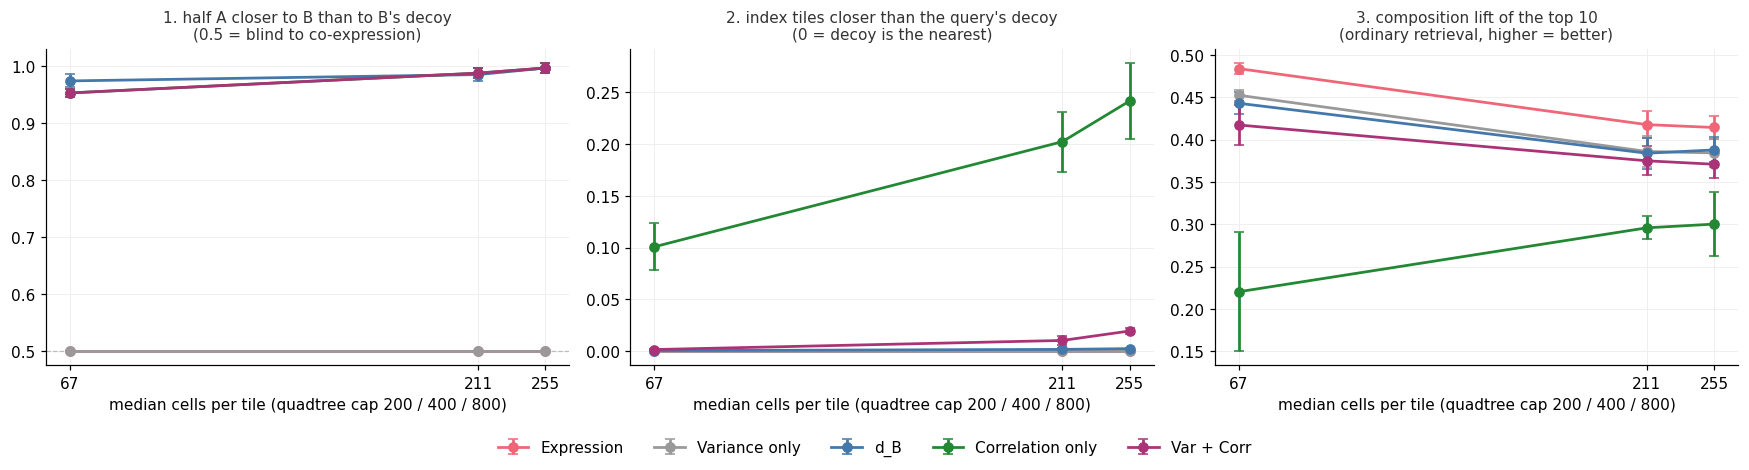

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
TITLES = {"half win": "1. half A closer to B than to B's decoy\n(0.5 = blind to co-expression)",
          "decoy rank": "2. index tiles closer than the query's decoy\n(0 = decoy is the nearest)",
          "composition lift": "3. composition lift of the top 10\n(ordinary retrieval, higher = better)"}
for ax, t in zip(axes, TESTS):
    for m in METHODS:
        mean = [seed_means.loc[c][f"{t} | {m}"].mean() for c in CAPS]
        sd_ = [seed_means.loc[c][f"{t} | {m}"].std() for c in CAPS]
        x = [int(seed_means.loc[c]["median cells"].iloc[0]) for c in CAPS]
        ax.errorbar(x, mean, yerr=sd_, marker="o", ms=6, lw=1.8, capsize=3, color=COLORS[m], label=m)
    if t == "half win":
        ax.axhline(0.5, color="#bbbbbb", lw=0.8, ls="--")
    ax.set_xscale("log")
    ax.set_xticks(x, [str(v) for v in x])
    ax.minorticks_off()
    ax.set_xlabel("median cells per tile (quadtree cap 200 / 400 / 800)")
    ax.set_title(TITLES[t], color="#333333", fontsize=10)
    ax.grid(color="#eeeeee", lw=0.6)
    ax.set_axisbelow(True)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(METHODS), frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## Control: is test 1 just cell size?

Within a cell type, a bigger (or better captured) cell has more of *every* transcript, so all genes co-vary for a
technical reason, and the decoy destroys that too. Test 1 is repeated on counts normalised per cell (each cell scaled
to the median total count over all panel genes), which removes most of the size co-variation. For a like-for-like
comparison both versions use the same queries and the same gene blocks (the last layout above, niche of the nearest
tile under raw d_B). If the win stays well above 0.5 after normalisation, the co-expression is not just cell size.

In [7]:
lib = np.asarray(adata.X.sum(1)).ravel()
scale = np.median(lib) / np.maximum(lib, 1)
CTRL = []
for cap in CAPS[:2]:
    tiles = build_quadtree_tiles(xy, max_pts=cap, min_side=0.0, max_depth=40)
    for seed in SEEDS:
        rng = np.random.default_rng(100 + seed)
        _, test = sd.split_tiles(len(tiles), seed=seed, test_ratio=TEST_RATIO)
        for q in test:
            idx = tiles[q].idx
            perm = rng.permutation(idx.size)
            a, b = perm[: idx.size // 2], perm[idx.size // 2:]
            row = {"cap": cap, "seed": seed}
            for name, X in (("raw", cells(idx)), ("size-normalised", cells(idx) * scale[idx, None])):
                types = fine_id[idx]
                fa, fb, fbd = features(X[a]), features(X[b]), features(decoy(X[b], types[b], rng))
                k = min(VEC)   # same blocks for both versions
                for m in ("d_B", "Correlation only"):
                    da, dd = pair_distance(fa, fb, k, 1.0)[m], pair_distance(fa, fbd, k, 1.0)[m]
                    row[f"{name} | {m}"] = float(da < dd)
            CTRL.append(row)
CTRL = pd.DataFrame(CTRL)
ctrl = CTRL.groupby(["cap", "seed"]).mean().groupby("cap")
pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(ctrl[c].mean(), ctrl[c].std())]
              for c in CTRL.columns[2:]}, index=[f"cap {c}" for c in CAPS[:2]])   # test 1 win rate, mean ± s.d.

[2026-10-30 00:28:36,683] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)


[2026-10-30 00:29:38,844] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 5 low-density tile(s) (335 spots)


,raw | d_B,raw | Correlation only,size-normalised | d_B,size-normalised | Correlation only
cap 200,0.963 ± 0.019,0.934 ± 0.015,0.725 ± 0.029,0.554 ± 0.037
cap 400,0.985 ± 0.023,0.962 ± 0.020,0.746 ± 0.028,0.574 ± 0.044


## Reading the results (Slurm job 23975, 30 Oct; breast, seeds 0–4)

**There is a case where expression fails and d_B works:** telling a tile from an expression-identical tile that lacks
its co-expression.
- **Test 1** (half A against half B and B's decoy): expression and variance are blind by construction (0.5; the two
  lines overlap). d_B wins 97 % of pairs at production size (67 cells), rising to 99.6 % with larger tiles.
- **Most of that is cell size.** After per-cell normalisation d_B drops to 0.73 ± 0.03 (cap 200) and 0.75 ± 0.03
  (cap 400), and correlation-only to 0.55–0.57. The rest, about 0.25 above chance, is co-expression inside cell types
  that is neither expression nor cell size, and it reproduces across disjoint halves of a tile's cells. d_B keeps more
  of it than correlation-only, probably because its log-covariance weights well-measured (highly expressed) genes more.

**But it does not decide ordinary searches.**
- **Test 2**: under d_B the query's expression-identical decoy is closer than 99.8 % of real index tiles. Differences
  in expression and variance between real tiles are far larger than differences in co-expression, so co-expression
  almost never changes who the nearest neighbours are.
- Correlation-only does let co-expression count (10–24 % of real tiles beat the decoy, more for bigger tiles), but at a
  large cost in ordinary retrieval.
- **Test 3**: composition lift falls from 0.443 to 0.220 at production size. Var + Corr sits between the two.

**What this supports.** Spindle carries information that expression cannot carry: within-type co-expression,
reproducible within a tile, distinguishable at about 75 % against 50 % once cell size is removed. It shows up when
expression is held fixed (re-ranking among expression-matched candidates, or comparing tiles of the same composition),
not in open search, where expression differences dominate.

**Caveats.** The decoys are synthetic. Part of the raw signal is cell size, which can be biology (cell state) or
capture. Some within-type co-expression may be segmentation spillover from neighbouring cells. This is one section with
one annotation.

**Possible next test:** a real, non-synthetic version, where queries are re-ranked among their expression top-50 by d_B
and scored on held-out cells, to see whether this signal picks biologically matching tiles.
